In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, mean_squared_error,
                             mean_absolute_error, log_loss)

np.random.seed(42)
df = pd.read_csv("data/matches.csv")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (1243, 31)


,event_name,season,match_number,date,city,venue,team1,team2,toss_winner,toss_decision,...,umpire2,tv_umpire,reserve_umpire,match_type,overs_limit,balls_per_over,gender,team_type,team1_players,team2_players
0,Indian Premier League,2007/08,1.0,18-04-2008,Bangalore,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,...,RE Koertzen,AM Saheba,VN Kulkarni,T20,20,6,male,club,"R Dravid, W Jaffer, V Kohli, JH Kallis, CL Whi...","SC Ganguly, BB McCullum, RT Ponting, DJ Hussey..."
1,Indian Premier League,2007/08,2.0,19-04-2008,Chandigarh,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,...,SL Shastri,RB Tiffin,MSS Ranawat,T20,20,6,male,club,"K Goel, JR Hopes, KC Sangakkara, Yuvraj Singh,...","PA Patel, ML Hayden, MEK Hussey, MS Dhoni, SK ..."
2,Indian Premier League,2007/08,3.0,19-04-2008,Delhi,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,...,GA Pratapkumar,IL Howell,Unknown,T20,20,6,male,club,"G Gambhir, V Sehwag, S Dhawan, MK Tiwary, KD K...","T Kohli, YK Pathan, SR Watson, M Kaif, DS Lehm..."
3,Indian Premier League,2007/08,4.0,20-04-2008,Kolkata,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,...,K Hariharan,Asad Rauf,F Gomes,T20,20,6,male,club,"WP Saha, BB McCullum, RT Ponting, SC Ganguly, ...","AC Gilchrist, Y Venugopal Rao, VVS Laxman, A S..."
4,Indian Premier League,2007/08,5.0,20-04-2008,Mumbai,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,...,DJ Harper,AV Jayaprakash,SN Bandekar,T20,20,6,male,club,"L Ronchi, ST Jayasuriya, DJ Thornely, RV Uthap...","S Chanderpaul, R Dravid, LRPL Taylor, JH Kalli..."


In [4]:
print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and missing-value overview:")
df.info()

print("\nSummary of numeric columns:")
display(df.describe())

Dataset dimensions: (1243, 31)

Column names:
['event_name', 'season', 'match_number', 'date', 'city', 'venue', 'team1', 'team2', 'toss_winner', 'toss_decision', 'team1_runs', 'team1_wickets', 'team2_runs', 'team2_wickets', 'winner', 'result_type', 'win_by_runs', 'win_by_wickets', 'player_of_match', 'match_referee', 'umpire1', 'umpire2', 'tv_umpire', 'reserve_umpire', 'match_type', 'overs_limit', 'balls_per_over', 'gender', 'team_type', 'team1_players', 'team2_players']

Data types and missing-value overview:
<class 'pandas.DataFrame'>
RangeIndex: 1243 entries, 0 to 1242
Data columns (total 31 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   event_name       1243 non-null   str    
 1   season           1243 non-null   str    
 2   match_number     1169 non-null   float64
 3   date             1243 non-null   str    
 4   city             1243 non-null   str    
 5   venue            1243 non-null   str    
 6   team1           

,match_number,team1_runs,team1_wickets,team2_runs,team2_wickets,win_by_runs,win_by_wickets,overs_limit,balls_per_over
count,1169.000000,1243.000000,1243.000000,1243.000000,1243.000000,1243.000000,1243.000000,1243.0,1243.0
mean,31.921300,165.851167,5.956557,157.349155,5.873693,13.932422,3.276750,20.0,6.0
std,18.626023,35.490847,2.309341,34.613073,2.646538,23.861556,3.358216,0.0,0.0
min,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,20.0,6.0
25%,16.000000,144.000000,4.000000,138.000000,4.000000,0.000000,0.000000,20.0,6.0
50%,32.000000,165.000000,6.000000,160.000000,6.000000,0.000000,3.000000,20.0,6.0
75%,47.000000,189.000000,8.000000,179.000000,8.000000,20.000000,6.000000,20.0,6.0
max,72.000000,287.000000,10.000000,265.000000,12.000000,146.000000,10.000000,20.0,6.0


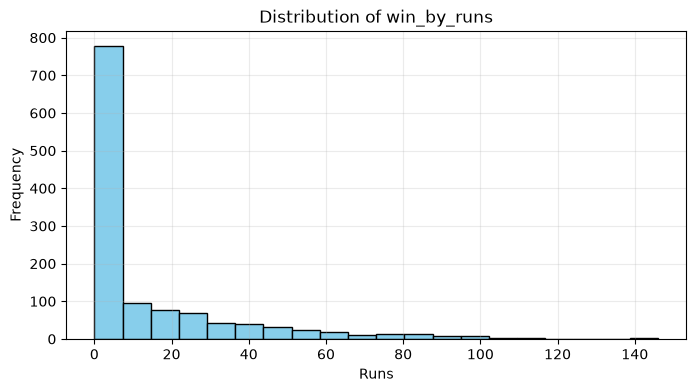

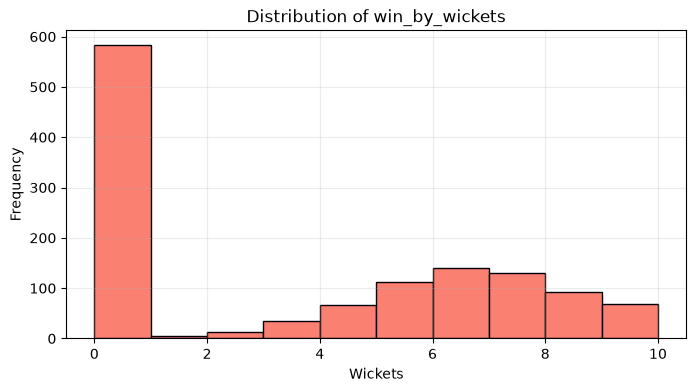

In [10]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

column_to_plot_1 = "win_by_runs"

plt.figure(figsize=(8, 4))
plt.hist(df[column_to_plot_1].dropna(), bins=20, edgecolor="black", color="skyblue")
plt.title(f"Distribution of {column_to_plot_1}")
plt.xlabel("Runs")
plt.ylabel("Frequency")
plt.grid(alpha=0.25)
plt.show()

column_to_plot_2 = "win_by_wickets"

plt.figure(figsize=(8, 4))
plt.hist(df[column_to_plot_2].dropna(), bins=10, edgecolor="black", color="salmon")
plt.title(f"Distribution of {column_to_plot_2}")
plt.xlabel("Wickets")
plt.ylabel("Frequency")
plt.grid(alpha=0.25)
plt.show()